In [1]:
"""
Pearson correlation between the normalized spectral disturbance index (0-1)
and OPERA VEG-ANOM-MAX (0-100 percent anomaly).

The two rasters do not necessarily share a grid, extent, or resolution, and
each has its own nodata convention. Correlating them requires putting them on
one grid and keeping only the pixels that are real observations in BOTH.
"""

import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import reproject
from scipy import stats

# Defines paths for the OPERA and spectral composite index rasters.
INDEX_PATH = r"C:\Users\nkaplunm\Documents\python_scripts\data\index_composite_spectral_2024_forest.tif"
ANOM_PATH = r"C:\Users\nkaplunm\Documents\python_scripts\dist_bands\exports\VEG-ANOM-MAX_mosaic_filtered2024-09-30_4.tif"

# Thresholds for valid pixels in the index and anomaly rasters. Pixels below these thresholds are excluded from the correlation analysis.
INDEX_MIN = 0.2    # normalized index, 0-1
ANOM_MIN_PCT = 10  # OPERA anomaly, in percent (0-100 native units)

def read_band1(path):
    """
    opens and reads the first band of a raster file, returning the data array, profile metadata, and nodata value.
    """
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float64")
        return arr, src.profile, src.nodata


def align_to(reference_path, moving_path):
    """
    Resamples the moving raster onto the reference raster's exact grid.

    The index is the finer/reference grid here; VEG-ANOM-MAX is resampled to
    match it. Nearest-neighbor is used because introducing averaged values would
    correlate a real index pixel against an anomaly value that was never
    actually observed there.
    """
    with rasterio.open(reference_path) as ref:
        ref_arr = ref.read(1).astype("float64")
        ref_profile = ref.profile
        ref_nodata = ref.nodata

    # reprojects the moving raster to the reference grid, filling a new array with NaNs for nodata.
    with rasterio.open(moving_path) as mov:
        mov_nodata = mov.nodata
        dst = np.full((ref.height, ref.width), np.nan, dtype="float64")
        reproject(
            source=rasterio.band(mov, 1),
            destination=dst,
            src_transform=mov.transform,
            src_crs=mov.crs,
            dst_transform=ref.transform,
            dst_crs=ref.crs,
            resampling=Resampling.nearest,
            src_nodata=mov_nodata,
            dst_nodata=np.nan,
        )
    # returns the reference array, its nodata value, the resampled moving array, and its nodata value.
    return ref_arr, ref_nodata, dst, mov_nodata


def main():
    # Index is the reference grid; ANOM-MAX gets warped to match it.
    index, index_nodata, anom, anom_nodata = align_to(INDEX_PATH, ANOM_PATH)

    print(f"grid: {index.shape}  (index as reference)")
    print(f"index nodata: {index_nodata}   anom nodata: {anom_nodata}")

    # --- validity masks -----------------------------------------------------
    # remove pixels that are nodata or outside the valid range for each raster, and then find the intersection of valid pixels in both rasters.
    index_valid = np.isfinite(index)
    if index_nodata is not None:
        index_valid &= (index != index_nodata)
    # a normalized 0-1 index: guard against fill values that slipped outside range
    index_valid &= (index >= 0) & (index <= 1)
    index_valid &= (index >= INDEX_MIN)   # threshold

    anom_valid = np.isfinite(anom)
    if anom_nodata is not None:
        anom_valid &= (anom != anom_nodata)
    anom_valid &= (anom != 255)  # explicit OPERA fill, in case nodata was unset
    anom_valid &= (anom >= ANOM_MIN_PCT)  # threshold (percent units)

    both = index_valid & anom_valid
    n = int(both.sum())
    print(f"thresholds: index >= {INDEX_MIN}, anom >= {ANOM_MIN_PCT}%")
    print(f"index-valid px: {int(index_valid.sum()):,}")
    print(f"anom-valid px:  {int(anom_valid.sum()):,}")
    print(f"valid in BOTH:  {n:,}")
    print(f"Percent Overlap:  {(float(n / anom_valid.sum() * 100)):,}%")

    x = index[both]
    y = anom[both] / 100.0   # rescale 0-100 -> 0-1 for a shared axis.

    # correlations 
    r, p = stats.pearsonr(x, y)
    rho, p_s = stats.spearmanr(x, y) 

    print(f"\nn = {n:,}")
    print(f"Pearson  r = {r:.4f}")
    print(f"Spearman rho = {rho:.4f}")
    print(f"R^2 (linear) = {r**2:.4f}")


if __name__ == "__main__":
    main()


C:\Users\nkaplunm\AppData\Local\Temp\5\ipykernel_35364\1200981167.py:43: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  ref_arr = ref.read(1).astype("float64")


grid: (7425, 10911)  (index as reference)
index nodata: nan   anom nodata: 255.0
thresholds: index >= 0.2, anom >= 10%
index-valid px: 4,433,559
anom-valid px:  596,039
valid in BOTH:  446,039
Percent Overlap:  74.83386154261717%

n = 446,039
Pearson  r = 0.1007
Spearman rho = 0.2029
R^2 (linear) = 0.0101


C:\Users\nkaplunm\AppData\Local\Temp\5\ipykernel_35364\1539341292.py:23: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  index = ref.read(1).astype("float64")


saved index_vs_anom.png
OPERA:  mean=18.7%  std=10.2  IQR=[12, 22]
index:  mean=0.621  std=0.177  IQR=[0.50, 0.77]
fraction of OPERA pixels below 15%: 42.8%


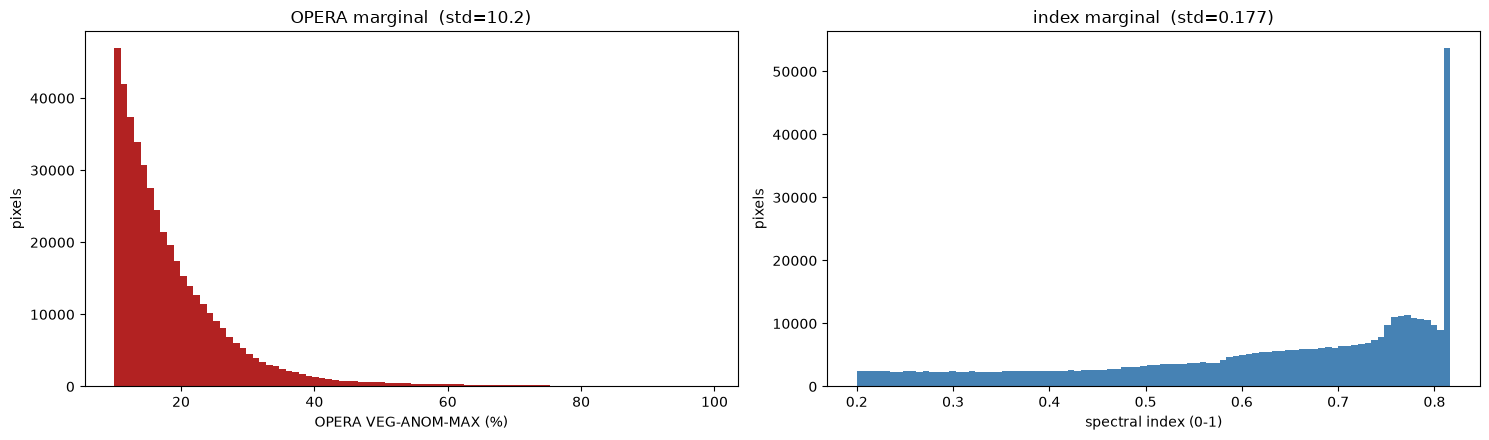

In [8]:
"""
Visualize the index vs OPERA VEG-ANOM-MAX relationship over the disturbed
population, to confirm reason for the weak r.

"""

import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import reproject
import matplotlib.pyplot as plt

# Defines paths for the OPERA and spectral composite index rasters.
INDEX_PATH = r"C:\Users\nkaplunm\Documents\python_scripts\data\index_composite_spectral_2024_forest.tif"
ANOM_PATH = r"C:\Users\nkaplunm\Documents\python_scripts\dist_bands\exports\VEG-ANOM-MAX_mosaic_filtered2024-09-30_4.tif"

# Thresholds for valid pixels in the index and anomaly rasters. Pixels below these thresholds are excluded from the correlation analysis.
INDEX_MIN = 0.2    # normalized index, 0-1
ANOM_MIN_PCT = 10  # OPERA anomaly, in percent (0-100 native units)

# opens the index dataset to get its dimensions, transform, and CRS. The index is used as the reference grid for resampling the anomaly dataset.
with rasterio.open(INDEX_PATH) as ref:
    index = ref.read(1).astype("float64")
    H, W, t, c = ref.height, ref.width, ref.transform, ref.crs

# opens the anomaly dataset and resamples it to the index grid, filling a new array with NaNs for nodata.
with rasterio.open(ANOM_PATH) as mov:
    anom = np.full((H, W), np.nan)
    reproject(rasterio.band(mov, 1), anom,
              src_transform=mov.transform, src_crs=mov.crs,
              dst_transform=t, dst_crs=c,
              resampling=Resampling.nearest,
              src_nodata=mov.nodata, dst_nodata=np.nan)

# identify valid pixels in both rasters based on the defined thresholds and create a mask for pixels that are valid in both datasets.
iv = np.isfinite(index) & (index >= INDEX_MIN) & (index <= 1)
av = np.isfinite(anom) & (anom != 255) & (anom >= ANOM_MIN_PCT)
both = iv & av
x = index[both]
y = anom[both]

# creates the two plots 
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

ax[0].hist(y, bins=90, color="firebrick")
ax[0].set_xlabel("OPERA VEG-ANOM-MAX (%)")
ax[0].set_ylabel("pixels")
ax[0].set_title(f"OPERA marginal  (std={y.std():.1f})")

ax[1].hist(x, bins=90, color="steelblue")
ax[1].set_xlabel("spectral index (0-1)")
ax[1].set_ylabel("pixels")
ax[1].set_title(f"index marginal  (std={x.std():.3f})")

# prints out the statistics for the OPERA and index datasets, including mean, standard deviation, interquartile range (IQR), and the fraction of OPERA pixels below 15%.
plt.tight_layout()
plt.savefig("index_vs_anom.png", dpi=150)
print("saved index_vs_anom.png")
print(f"OPERA:  mean={y.mean():.1f}%  std={y.std():.1f}  "
      f"IQR=[{np.percentile(y,25):.0f}, {np.percentile(y,75):.0f}]")
print(f"index:  mean={x.mean():.3f}  std={x.std():.3f}  "
      f"IQR=[{np.percentile(x,25):.2f}, {np.percentile(x,75):.2f}]")
print(f"fraction of OPERA pixels below 15%: {(y < 15).mean():.1%}")
